*** the project is about diabetes prediction using random forest classifier. i start by doing exploratory Data analysis

In [3]:
#importing libraries
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.metrics import confusion_matrix,accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt



In [4]:
# reading the file 
df=pd.read_csv("balanced_diabetes_500_patients.csv")
df.head(10)

,Patient_ID,Age,Family_History,Genetic_Risk_Score,BMI,Physical_Activity_Hours_Per_Week,Diet_Quality_Score,Diabetes_Status
0,P_1000,65,1,0.43,30.4,0.5,3,1
1,P_1001,31,0,0.37,21.5,3.0,7,0
2,P_1002,81,1,0.43,33.0,3.0,5,1
3,P_1003,32,0,0.26,28.3,5.4,8,0
4,P_1004,25,0,0.60,26.2,6.3,5,0
5,P_1005,38,1,0.84,29.7,1.7,3,1
6,P_1006,55,0,0.57,22.5,3.4,4,1
7,P_1007,57,0,0.38,20.0,6.2,5,0
8,P_1008,43,0,0.39,26.7,3.0,7,0
9,P_1009,66,1,0.50,29.7,0.0,2,1


In [5]:
df.describe()

,Age,Family_History,Genetic_Risk_Score,BMI,Physical_Activity_Hours_Per_Week,Diet_Quality_Score,Diabetes_Status
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,50.054000,0.386000,0.520600,27.833600,3.764200,5.544000,0.500000
std,17.020531,0.487318,0.239779,5.396402,2.261824,2.587945,0.500501
min,18.000000,0.000000,0.110000,17.000000,0.000000,1.000000,0.000000
25%,38.000000,0.000000,0.337500,23.775000,2.100000,4.000000,0.000000
50%,49.000000,0.000000,0.510000,27.300000,3.600000,5.000000,0.500000
75%,61.000000,1.000000,0.700000,31.700000,5.400000,8.000000,1.000000
max,84.000000,1.000000,0.990000,44.200000,10.100000,10.000000,1.000000


In [6]:
df.duplicated().sum()
df.isna().sum()

Patient_ID                          0
Age                                 0
Family_History                      0
Genetic_Risk_Score                  0
BMI                                 0
Physical_Activity_Hours_Per_Week    0
Diet_Quality_Score                  0
Diabetes_Status                     0
dtype: int64

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Patient_ID                        500 non-null    str    
 1   Age                               500 non-null    int64  
 2   Family_History                    500 non-null    int64  
 3   Genetic_Risk_Score                500 non-null    float64
 4   BMI                               500 non-null    float64
 5   Physical_Activity_Hours_Per_Week  500 non-null    float64
 6   Diet_Quality_Score                500 non-null    int64  
 7   Diabetes_Status                   500 non-null    int64  
dtypes: float64(3), int64(4), str(1)
memory usage: 31.4 KB


*** Data visualization

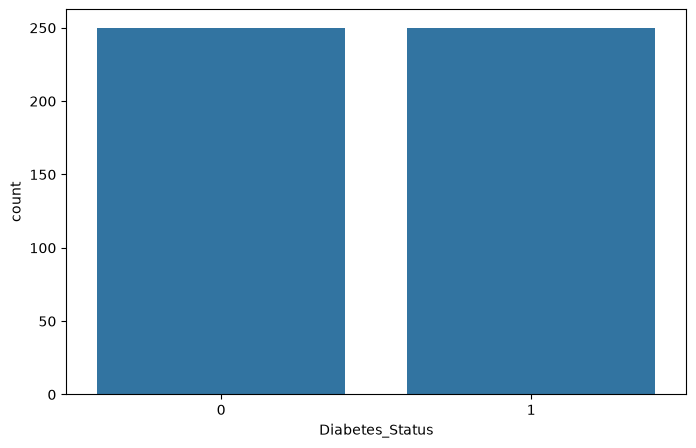

In [7]:
plt.figure(figsize=(8,5))
sns.countplot(x="Diabetes_Status",data=df)
plt.show()

*** checking outliers

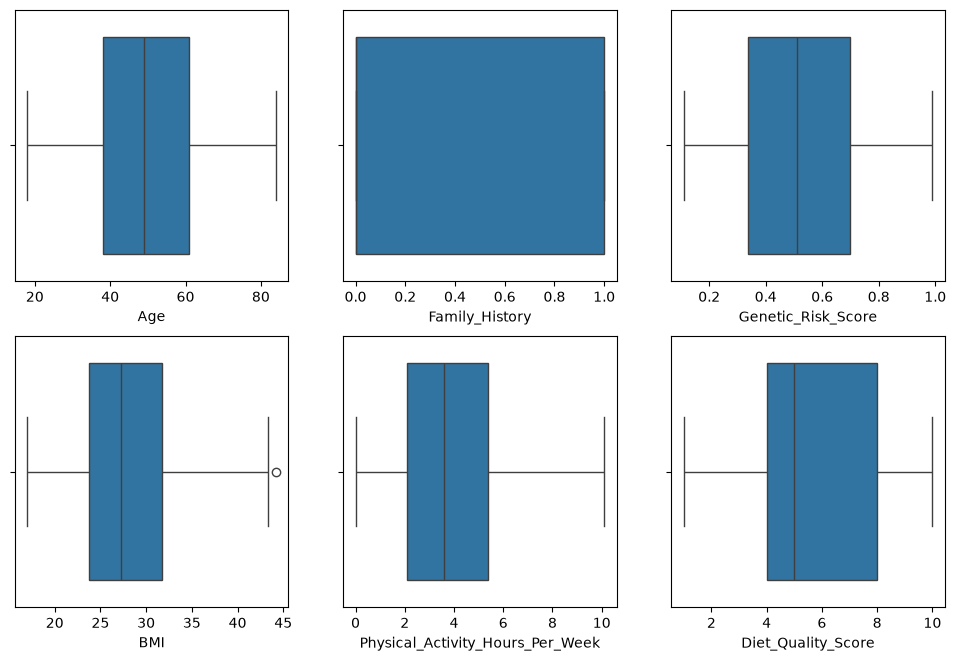

In [9]:
plt.figure(figsize=(12,12))
for i,col in enumerate(['Age','Family_History','Genetic_Risk_Score','BMI','Physical_Activity_Hours_Per_Week','Diet_Quality_Score']):
    plt.subplot(3,3,i+1)
    sns.boxplot(x=col,data=df)
    plt.show

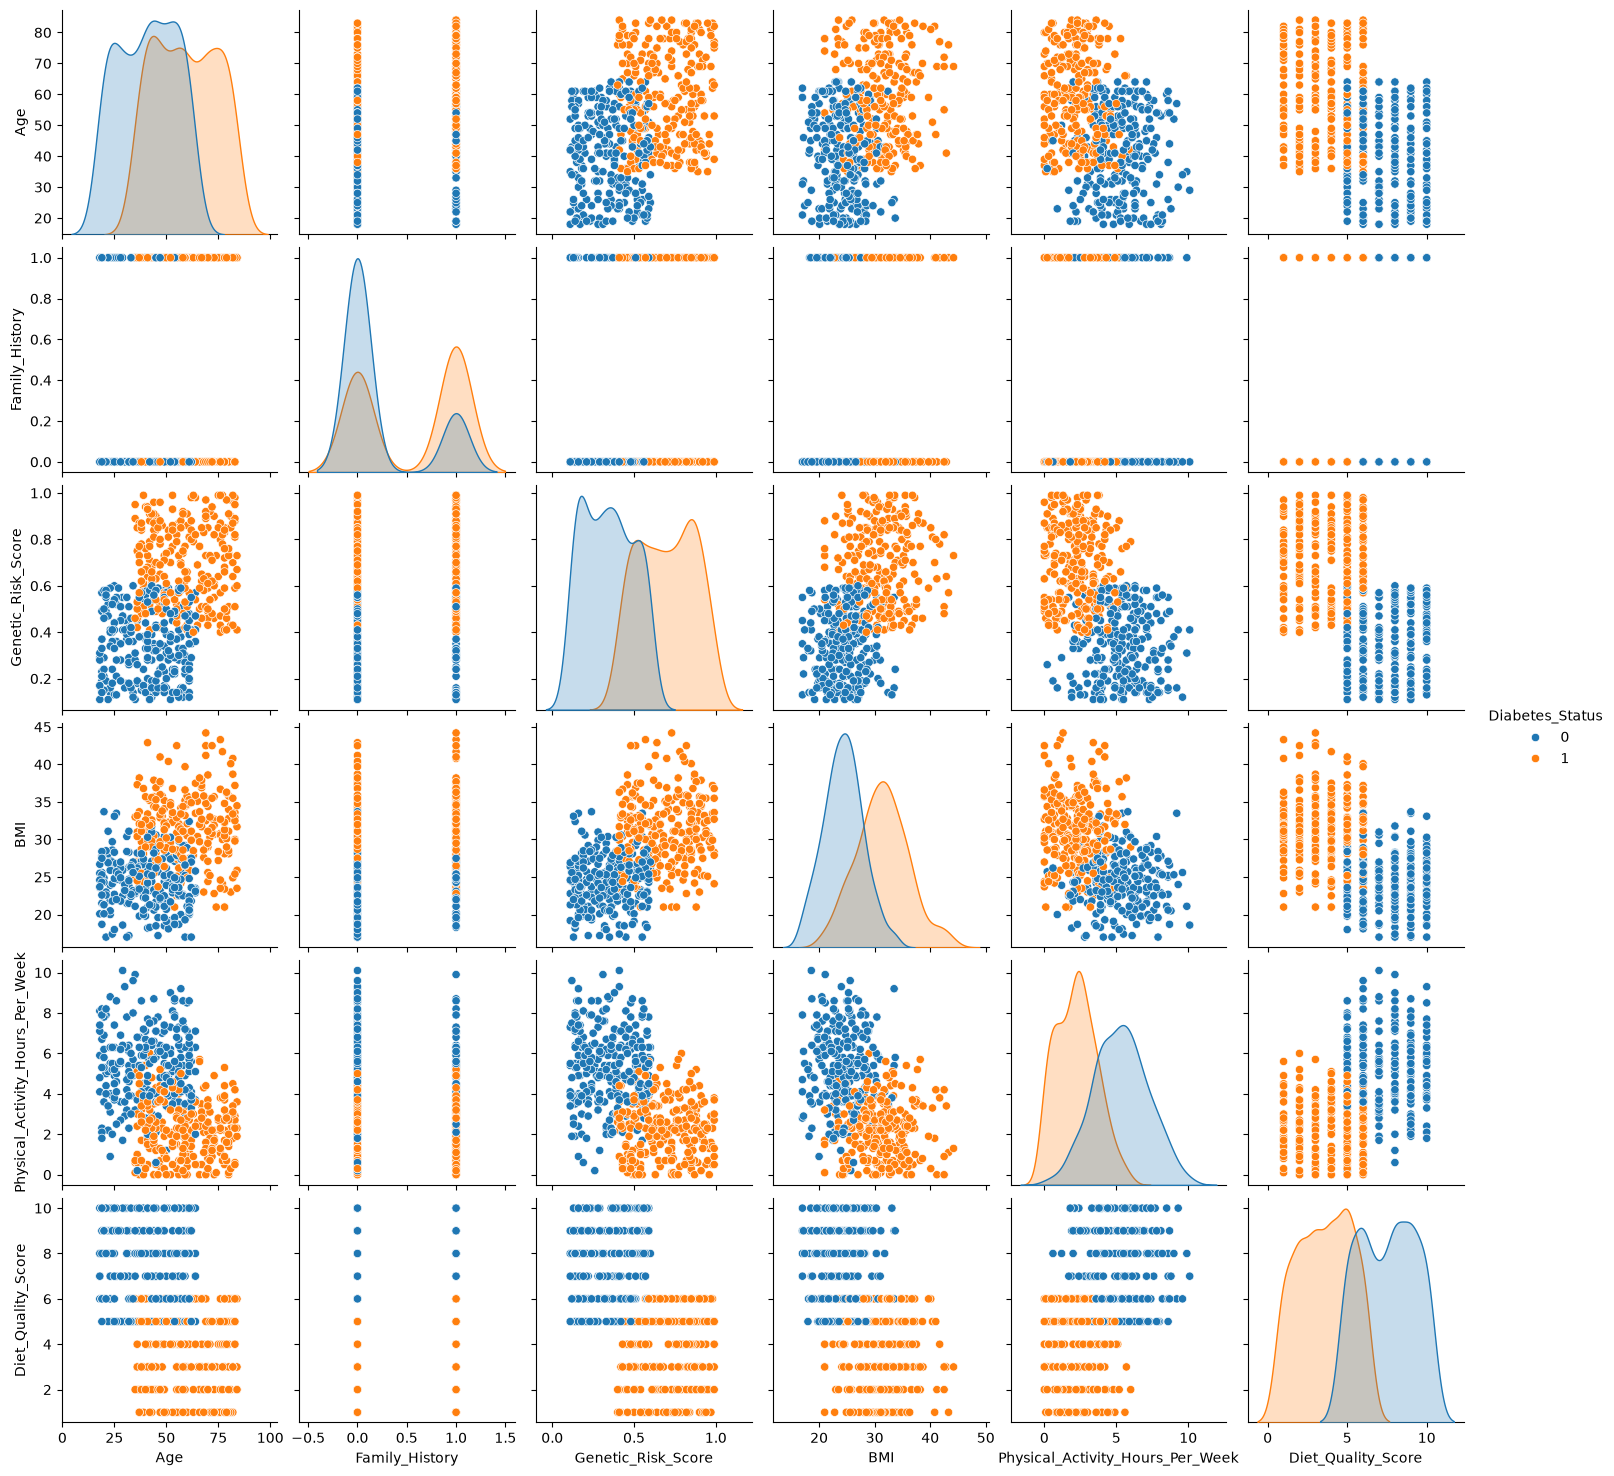

In [11]:
sns.pairplot(df,hue='Diabetes_Status')
plt.show()

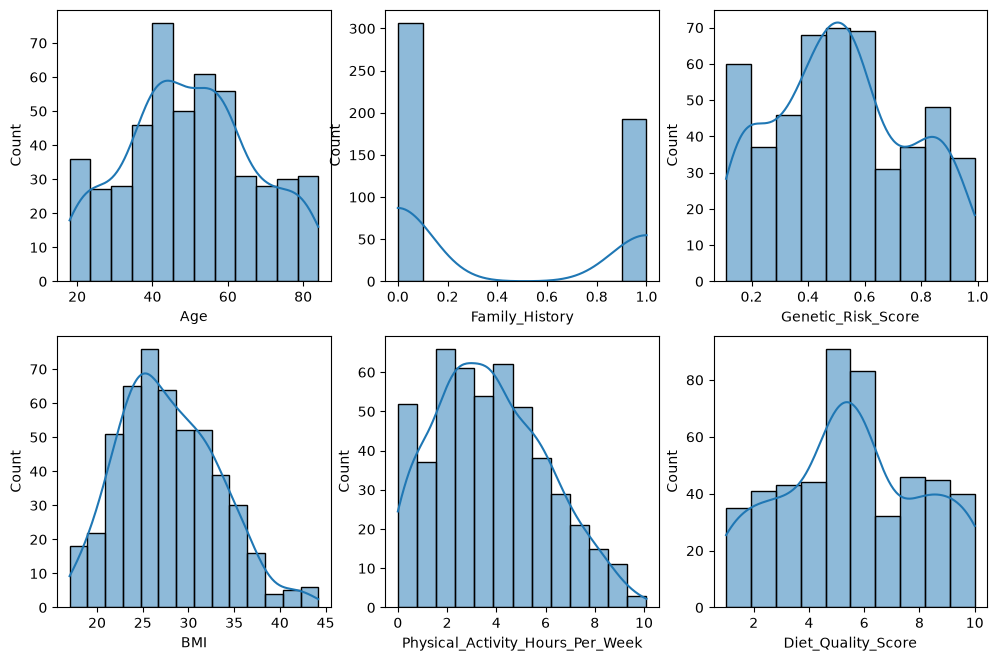

In [12]:
plt.figure(figsize=(12,12))
for i,col in enumerate(['Age','Family_History','Genetic_Risk_Score','BMI','Physical_Activity_Hours_Per_Week','Diet_Quality_Score']):
    plt.subplot(3,3,i+1)
    sns.histplot(x=col,data=df,kde=True)
    plt.show

*** creating and training the model

In [8]:
#importing libraries
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix,accuracy_score
from sklearn.model_selection import train_test_split

# loading the file and separating features
df=pd.read_csv('balanced_diabetes_500_patients.csv')
X=df.drop(columns=['Diabetes_Status','Patient_ID'])
y=df['Diabetes_Status']

#splitting data into training and testing
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

#Creating model
model=RandomForestClassifier(n_estimators=100,max_depth=2,random_state=42)
model.fit(X_train,y_train)
y_pred=model.predict(X_test)

#checking accuracy
accuracy=accuracy_score(y_test,y_pred)
matrix=confusion_matrix(y_test,y_pred)

print('accuracy:',accuracy)
print('confusion matrix:',matrix)

#saving the model
saved_model=joblib.dump(model,'diabetes prediction')
print("model saved succesfully")



accuracy: 1.0
confusion matrix: [[43  0]
 [ 0 57]]
model saved succesfully


**** loading the saved modeland using it to predict new patients data

In [9]:
# loading model
loaded_model=joblib.load('diabetes prediction')

#preparing new data
new_data=pd.DataFrame([{'Age':56,'Family_History':0,'Genetic_Risk_Score':0.31,'BMI':24.3,'Physical_Activity_Hours_Per_Week':3,'Diet_Quality_Score':6,},
    {'Age':35,'Family_History':0,'Genetic_Risk_Score':0.25,'BMI':22.3,'Physical_Activity_Hours_Per_Week':5,'Diet_Quality_Score':8,},
    {'Age':61,'Family_History':1,'Genetic_Risk_Score':0.65,'BMI':33.7,'Physical_Activity_Hours_Per_Week':0.5,'Diet_Quality_Score':1,},
    {'Age':75,'Family_History':0,'Genetic_Risk_Score':0.31,'BMI':38,'Physical_Activity_Hours_Per_Week':0.3,'Diet_Quality_Score':0.5,}])

#making predictions
predictions=loaded_model.predict(new_data)

# Map 0 to 'Healthy' and 1 to 'Diabetic'
status_map = {0: 'Healthy', 1: 'Diabetic'}
readable_predictions = [status_map[p] for p in predictions]

print('According to the data, the patients are:', readable_predictions)



According to the data, the patients are: ['Healthy', 'Healthy', 'Diabetic', 'Diabetic']
